# 11 — Emerging Hotspot Analysis (Kalimantan)

**Purpose:** diagnose why the Logistic Regression benchmark is already strong, and test whether it is substantially weaker on **emerging hotspot detections** than on **persistent hotspot detections**.

This notebook is intentionally run **before** building GAT / wind-informed graph models.

## Main questions

1. Among positive next-day targets, how many are **persistent** versus **emerging**?
2. Is Logistic Regression much better at persistent detections than emerging detections?
3. Does adding weather features help specifically on emerging detections?
4. Where and when do emerging detections occur?

## Important interpretation

The target remains **next-day FIRMS detection**, not confirmed wildfire ignition.

- `target_fire_active_t1 = 1` means FIRMS activity is observed in the cell on the next day.
- `0` means **not detected**, not proven absence of fire.
- Therefore, the term **emerging hotspot** in this notebook means:

> a next-day positive detection in a cell that had **no observed FIRMS activity during the previous 7 days including the current prediction day**.

It must **not** be interpreted as confirmed new fire ignition.

## Main definition

For a row representing cell `i` at prediction day `t`:

- **Persistent positive:** `target_fire_active_t1 = 1` and at least one detection occurred in the same cell during `t-6 ... t`.
- **Emerging positive:** `target_fire_active_t1 = 1` and no detection occurred in the same cell during `t-6 ... t`.

A 3-day definition is also calculated as a sensitivity check.

In [2]:
# 1. Imports and reproducibility

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("Libraries loaded.")

Libraries loaded.


## 2. Resolve project paths

The earlier notebooks use:

- `data/intermediate/fire_kalimantan_cell_day_full.csv`
- `data/processed/karhut_ml_dataset_kalimantan.csv`

The code below searches several common project-root locations so it works both locally and, with minor adjustment, on Colab.

In [3]:
# 2. Project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    ml_candidate = candidate / "data" / "processed" / "karhut_ml_dataset_kalimantan.csv"
    fire_candidate = candidate / "data" / "intermediate" / "fire_kalimantan_cell_day_full.csv"

    if ml_candidate.exists() and fire_candidate.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root could not be detected automatically.\n"
        "Set PROJECT_ROOT manually to the folder containing data/intermediate and data/processed."
    )

ML_PATH = PROJECT_ROOT / "data" / "processed" / "karhut_ml_dataset_kalimantan.csv"
FIRE_PANEL_PATH = PROJECT_ROOT / "data" / "intermediate" / "fire_kalimantan_cell_day_full.csv"

RESULTS_DIR = PROJECT_ROOT / "model_results" / "emerging_hotspot"
FIGURES_DIR = RESULTS_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT    :", PROJECT_ROOT)
print("ML dataset      :", ML_PATH)
print("Fire panel      :", FIRE_PANEL_PATH)
print("Results         :", RESULTS_DIR)

PROJECT_ROOT    : c:\Users\Asus\Documents\skripsi-karhut
ML dataset      : c:\Users\Asus\Documents\skripsi-karhut\data\processed\karhut_ml_dataset_kalimantan.csv
Fire panel      : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\fire_kalimantan_cell_day_full.csv
Results         : c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot


## 3. Load the model-ready dataset and complete fire cell-day panel

The complete panel is required because the model-ready CSV contains engineered historical features but does not retain the original `fire_active` state for the current prediction day.

Using the complete panel lets us build an exact 7-day detection-history window ending at day `t`.

In [4]:
# 3. Load data

ml = pd.read_csv(ML_PATH, parse_dates=["date"])
fire = pd.read_csv(FIRE_PANEL_PATH, parse_dates=["date"])

ml = (
    ml
    .sort_values(["cell_id", "date"])
    .reset_index(drop=True)
)

fire = (
    fire
    .sort_values(["cell_id", "date"])
    .reset_index(drop=True)
)

print("ML shape          :", ml.shape)
print("ML date range     :", ml["date"].min().date(), "→", ml["date"].max().date())
print("ML unique cells   :", ml["cell_id"].nunique())
print()
print("Fire panel shape  :", fire.shape)
print("Fire date range   :", fire["date"].min().date(), "→", fire["date"].max().date())
print("Fire unique cells :", fire["cell_id"].nunique())

required_ml = {
    "cell_id", "date", "grid_lat", "grid_lon", "target_fire_active_t1"
}
required_fire = {
    "cell_id", "date", "grid_lat", "grid_lon",
    "fire_count", "fire_active", "target_fire_active_t1"
}

missing_ml = sorted(required_ml - set(ml.columns))
missing_fire = sorted(required_fire - set(fire.columns))

if missing_ml:
    raise ValueError(f"Missing ML columns: {missing_ml}")

if missing_fire:
    raise ValueError(f"Missing fire-panel columns: {missing_fire}")

assert ml.duplicated(["cell_id", "date"]).sum() == 0, "Duplicate cell-date rows in ML dataset."
assert fire.duplicated(["cell_id", "date"]).sum() == 0, "Duplicate cell-date rows in fire panel."

print("\nBasic schema checks passed.")

ML shape          : (34272, 29)
ML date range     : 2026-05-08 → 2026-09-10
ML unique cells   : 272

Fire panel shape  : (36448, 11)
Fire date range   : 2026-05-01 → 2026-09-11
Fire unique cells : 272

Basic schema checks passed.


## 4. Construct recent detection history

For each cell:

- `active_days_prev3_incl_t`: number of active cell-days during `t-2 ... t`
- `active_days_prev7_incl_t`: number of active cell-days during `t-6 ... t`

The window **includes day `t`**, because the forecasting question uses all information available through day `t` to predict day `t+1`.

We also reconstruct the next-day target directly from the fire panel as an integrity check.

In [5]:
# 4. Build 3-day and 7-day detection histories, INCLUDING current day t

fire["fire_active"] = fire["fire_active"].astype(int)

fire["active_days_prev3_incl_t"] = (
    fire
    .groupby("cell_id")["fire_active"]
    .transform(lambda s: s.rolling(window=3, min_periods=3).sum())
)

fire["active_days_prev7_incl_t"] = (
    fire
    .groupby("cell_id")["fire_active"]
    .transform(lambda s: s.rolling(window=7, min_periods=7).sum())
)

fire["fire_active_t1_check"] = (
    fire
    .groupby("cell_id")["fire_active"]
    .shift(-1)
)

context_cols = [
    "cell_id",
    "date",
    "fire_active",
    "fire_count",
    "active_days_prev3_incl_t",
    "active_days_prev7_incl_t",
    "fire_active_t1_check",
]

fire_context = fire[context_cols].copy()

display(
    fire_context[
        [
            "cell_id",
            "date",
            "fire_active",
            "active_days_prev3_incl_t",
            "active_days_prev7_incl_t",
            "fire_active_t1_check",
        ]
    ].head(12)
)

,cell_id,date,fire_active,active_days_prev3_incl_t,active_days_prev7_incl_t,fire_active_t1_check
0,Kalimantan_-0.75_108.00,2026-05-01,0,NaN,NaN,0.0
1,Kalimantan_-0.75_108.00,2026-05-02,0,NaN,NaN,0.0
2,Kalimantan_-0.75_108.00,2026-05-03,0,0.0,NaN,0.0
3,Kalimantan_-0.75_108.00,2026-05-04,0,0.0,NaN,0.0
4,Kalimantan_-0.75_108.00,2026-05-05,0,0.0,NaN,0.0
5,Kalimantan_-0.75_108.00,2026-05-06,0,0.0,NaN,0.0
6,Kalimantan_-0.75_108.00,2026-05-07,0,0.0,0.0,0.0
7,Kalimantan_-0.75_108.00,2026-05-08,0,0.0,0.0,0.0
8,Kalimantan_-0.75_108.00,2026-05-09,0,0.0,0.0,0.0
9,Kalimantan_-0.75_108.00,2026-05-10,0,0.0,0.0,0.0


## 5. Merge the exact fire context into the model-ready dataset

The merge must be one-to-one. The reconstructed next-day target must also match `target_fire_active_t1` from Notebook 04/05.

In [6]:
# 5. Merge and integrity checks

analysis = ml.merge(
    fire_context,
    on=["cell_id", "date"],
    how="left",
    validate="one_to_one",
)

if len(analysis) != len(ml):
    raise AssertionError("Row count changed after merge.")

context_missing = analysis[
    [
        "fire_active",
        "active_days_prev3_incl_t",
        "active_days_prev7_incl_t",
        "fire_active_t1_check",
    ]
].isna().sum()

print("Context missing values:")
display(context_missing.to_frame("missing"))

# The model-ready period begins after enough history is available,
# so 3-day/7-day history should be complete.
if analysis["active_days_prev7_incl_t"].isna().any():
    raise AssertionError(
        "7-day history contains missing values. Check date coverage or the merge."
    )

target_check_mask = analysis["fire_active_t1_check"].notna()

target_mismatch = (
    analysis.loc[target_check_mask, "target_fire_active_t1"].astype(int)
    !=
    analysis.loc[target_check_mask, "fire_active_t1_check"].astype(int)
).sum()

print("Target mismatches against fire panel:", target_mismatch)

if target_mismatch != 0:
    raise AssertionError(
        "The model-ready target does not match next-day fire_active from Notebook 03."
    )

print("Merge and target integrity checks passed.")

Context missing values:


,missing
fire_active,0
active_days_prev3_incl_t,0
active_days_prev7_incl_t,0
fire_active_t1_check,0


Target mismatches against fire panel: 0
Merge and target integrity checks passed.


## 6. Define persistent and emerging positive detections

### 7-day primary definition

- `Emerging`: target is positive and **0 active days** during `t-6 ... t`
- `Persistent`: target is positive and **≥1 active day** during `t-6 ... t`

### 3-day sensitivity definition

The same logic is repeated using `t-2 ... t`.

Negative target rows remain `Negative`.

This definition is deliberately about **observed detection history**, not confirmed fire ignition history.

In [7]:
# 6. Event-type labels

def make_event_type(df, history_col):
    y = df["target_fire_active_t1"].astype(int)
    history = df[history_col]

    return np.select(
        [
            y.eq(0),
            y.eq(1) & history.eq(0),
            y.eq(1) & history.gt(0),
        ],
        [
            "Negative",
            "Emerging",
            "Persistent",
        ],
        default="Unknown",
    )

analysis["event_type_7d"] = make_event_type(
    analysis,
    "active_days_prev7_incl_t"
)

analysis["event_type_3d"] = make_event_type(
    analysis,
    "active_days_prev3_incl_t"
)

analysis["target_date"] = analysis["date"] + pd.Timedelta(days=1)

print("7-day event types:")
display(analysis["event_type_7d"].value_counts().to_frame("rows"))

print("\n3-day event types:")
display(analysis["event_type_3d"].value_counts().to_frame("rows"))

7-day event types:


,rows
event_type_7d,
Negative,27990
Persistent,5779
Emerging,503



3-day event types:


,rows
event_type_3d,
Negative,27990
Persistent,5308
Emerging,974


## 7. Recreate the temporal split from Notebook 05

- Train: 2026-05-08 → 2026-07-31
- Validation: 2026-08-01 → 2026-08-31
- Test: 2026-09-01 → 2026-09-10

The **validation set** is the main set used in this exploratory analysis.

The test set should not be used to choose the later GAT / graph design.

In [8]:
# 7. Temporal split labels

TRAIN_END = pd.Timestamp("2026-07-31")
VAL_END = pd.Timestamp("2026-08-31")
TEST_END = pd.Timestamp("2026-09-10")

def assign_split(date):
    if date <= TRAIN_END:
        return "Train"
    elif date <= VAL_END:
        return "Validation"
    elif date <= TEST_END:
        return "Test"
    return "Outside"

analysis["split"] = analysis["date"].map(assign_split)

split_summary = (
    analysis
    .groupby("split")
    .agg(
        start=("date", "min"),
        end=("date", "max"),
        rows=("date", "size"),
        positives=("target_fire_active_t1", "sum"),
    )
)

split_summary["positive_rate"] = (
    split_summary["positives"] / split_summary["rows"]
)

display(split_summary)

,start,end,rows,positives,positive_rate
split,,,,,
Test,2026-09-01,2026-09-10,2720,869.0,0.319485
Train,2026-05-08,2026-07-31,23120,2553.0,0.110424
Validation,2026-08-01,2026-08-31,8432,2860.0,0.339184


## 8. How many positives are emerging vs persistent?

This is the first key output.

We report the composition separately for Train, Validation, and Test because the fire season changes strongly over time.

In [9]:
# 8. Event composition by split

def positive_composition(df, event_col):
    positive = df[df["target_fire_active_t1"].eq(1)].copy()

    out = (
        positive
        .groupby(["split", event_col])
        .size()
        .rename("count")
        .reset_index()
    )

    out["positive_total_in_split"] = (
        out.groupby("split")["count"].transform("sum")
    )

    out["share_of_positives"] = (
        out["count"] / out["positive_total_in_split"]
    )

    return out

composition_7d = positive_composition(analysis, "event_type_7d")
composition_3d = positive_composition(analysis, "event_type_3d")

print("=== Primary 7-day definition ===")
display(composition_7d)

print("\n=== Sensitivity 3-day definition ===")
display(composition_3d)

=== Primary 7-day definition ===


,split,event_type_7d,count,positive_total_in_split,share_of_positives
0,Test,Emerging,12,869,0.013809
1,Test,Persistent,857,869,0.986191
2,Train,Emerging,399,2553,0.156287
3,Train,Persistent,2154,2553,0.843713
4,Validation,Emerging,92,2860,0.032168
5,Validation,Persistent,2768,2860,0.967832



=== Sensitivity 3-day definition ===


,split,event_type_3d,count,positive_total_in_split,share_of_positives
0,Test,Emerging,43,869,0.049482
1,Test,Persistent,826,869,0.950518
2,Train,Emerging,732,2553,0.286722
3,Train,Persistent,1821,2553,0.713278
4,Validation,Emerging,199,2860,0.069580
5,Validation,Persistent,2661,2860,0.930420


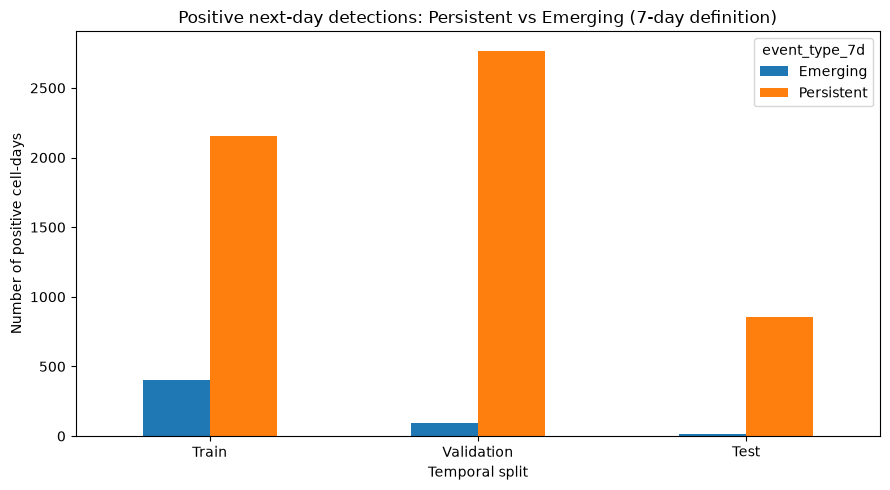

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\figures\event_composition_7d.png


In [10]:
# 8b. Plot positive composition using the 7-day definition

plot_df = (
    composition_7d
    .pivot(index="split", columns="event_type_7d", values="count")
    .fillna(0)
)

ordered_splits = [s for s in ["Train", "Validation", "Test"] if s in plot_df.index]
plot_df = plot_df.loc[ordered_splits]

ax = plot_df.plot(kind="bar", figsize=(9, 5))
ax.set_title("Positive next-day detections: Persistent vs Emerging (7-day definition)")
ax.set_xlabel("Temporal split")
ax.set_ylabel("Number of positive cell-days")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

fig_path = FIGURES_DIR / "event_composition_7d.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 9. Define the exact Notebook 05 feature sets

We reproduce:

- **Fire History Only:** 10 features
- **Fire History + Weather:** 20 features

This lets us ask a more useful question than overall PR-AUC alone:

> Does weather provide more value specifically for emerging detections?

In [11]:
# 9. Exact feature definitions from Notebook 04/05

fire_features = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

weather_features = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

features_10 = fire_features
features_20 = fire_features + weather_features
TARGET = "target_fire_active_t1"

missing_features = sorted(
    set(features_20 + [TARGET]) - set(analysis.columns)
)

if missing_features:
    raise ValueError(f"Missing modeling columns: {missing_features}")

print("Fire-history features :", len(features_10))
print("Full benchmark        :", len(features_20))

Fire-history features : 10
Full benchmark        : 20


## 10. Train the two Logistic Regression models

Configuration is matched to Notebook 05:

- `StandardScaler`
- `LogisticRegression`
- `class_weight="balanced"`
- `max_iter=1000`
- `random_state=42`

No test data are used for fitting.

In [12]:
# 10. Prepare train/validation/test data

train = analysis[analysis["split"].eq("Train")].copy()
val = analysis[analysis["split"].eq("Validation")].copy()
test = analysis[analysis["split"].eq("Test")].copy()

def fit_lr(feature_cols):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ])

    model.fit(
        train[feature_cols],
        train[TARGET].astype(int),
    )

    return model

lr_fire = fit_lr(features_10)
lr_full = fit_lr(features_20)

print("Both Logistic Regression models trained.")

Both Logistic Regression models trained.


## 11. Reproduce overall validation performance

The 20-feature model should approximately reproduce the Logistic Regression validation result from Notebook 05.

PR-AUC is threshold-free. Threshold-based metrics below use **0.50** to match the original baseline comparison.

In [13]:
# 11. Overall evaluation helper

def overall_metrics(model, df, feature_cols, threshold=0.5):
    y_true = df[TARGET].astype(int).to_numpy()
    y_prob = model.predict_proba(df[feature_cols])[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Threshold": threshold,
    }, y_prob

metrics_fire_val, prob_fire_val = overall_metrics(
    lr_fire, val, features_10, threshold=0.5
)

metrics_full_val, prob_full_val = overall_metrics(
    lr_full, val, features_20, threshold=0.5
)

overall_validation = pd.DataFrame([
    {"Model": "LR — Fire History Only", **metrics_fire_val},
    {"Model": "LR — Fire History + Weather", **metrics_full_val},
])

display(overall_validation)

,Model,PR-AUC,Precision,Recall,F1,Accuracy,Threshold
0,LR — Fire History Only,0.896141,0.767787,0.886713,0.822976,0.870612,0.5
1,LR — Fire History + Weather,0.901149,0.677419,0.925175,0.782146,0.825190,0.5


## 12. Evaluate Persistent vs Emerging positives

### Why we use recall here

Within the `Persistent` and `Emerging` subsets, **every row is a positive target**.

Therefore:

- **Recall** is meaningful: how many positive events in that subgroup were detected by the model?
- Mean/median predicted probability are also useful.
- **Precision is not a subgroup metric here**, because precision requires false-positive negative cases in the denominator.

This is the central diagnostic of Notebook 11.

In [14]:
# 12. Positive-subgroup evaluation

def positive_subgroup_metrics(
    df,
    probabilities,
    event_col="event_type_7d",
    threshold=0.5,
):
    work = df.copy().reset_index(drop=True)
    work["probability"] = probabilities
    work["prediction"] = (work["probability"] >= threshold).astype(int)

    rows = []

    for event_type in ["Persistent", "Emerging"]:
        group = work[work[event_col].eq(event_type)].copy()

        if len(group) == 0:
            rows.append({
                "Event Type": event_type,
                "N Positives": 0,
                "Recall": np.nan,
                "Mean Probability": np.nan,
                "Median Probability": np.nan,
                "P25 Probability": np.nan,
                "P75 Probability": np.nan,
            })
            continue

        rows.append({
            "Event Type": event_type,
            "N Positives": len(group),
            "Recall": group["prediction"].mean(),
            "Mean Probability": group["probability"].mean(),
            "Median Probability": group["probability"].median(),
            "P25 Probability": group["probability"].quantile(0.25),
            "P75 Probability": group["probability"].quantile(0.75),
        })

    return pd.DataFrame(rows)

subgroup_fire_val = positive_subgroup_metrics(
    val,
    prob_fire_val,
    event_col="event_type_7d",
    threshold=0.5,
)
subgroup_fire_val.insert(0, "Model", "LR — Fire History Only")

subgroup_full_val = positive_subgroup_metrics(
    val,
    prob_full_val,
    event_col="event_type_7d",
    threshold=0.5,
)
subgroup_full_val.insert(0, "Model", "LR — Fire History + Weather")

subgroup_validation = pd.concat(
    [subgroup_fire_val, subgroup_full_val],
    ignore_index=True,
)

display(subgroup_validation)

,Model,Event Type,N Positives,Recall,Mean Probability,Median Probability,P25 Probability,P75 Probability
0,LR — Fire History Only,Persistent,2768,0.914740,0.894581,0.999952,0.887473,1.000000
1,LR — Fire History Only,Emerging,92,0.043478,0.335832,0.318472,0.318472,0.318472
2,LR — Fire History + Weather,Persistent,2768,0.942919,0.907788,0.999877,0.913088,1.000000
3,LR — Fire History + Weather,Emerging,92,0.391304,0.447740,0.449310,0.336163,0.580847


## 13. Quantify whether weather helps emerging detections

We calculate the change from:

`Fire History Only → Fire History + Weather`

separately for Persistent and Emerging positives.

A meaningful improvement specifically on Emerging events would support the idea that contextual environmental information is useful when local fire persistence is absent.

In [15]:
# 13. Weather contribution by subgroup

comparison = (
    subgroup_validation
    .pivot(
        index="Event Type",
        columns="Model",
        values=["Recall", "Mean Probability", "Median Probability"],
    )
)

display(comparison)

def get_metric(df, model, event, metric):
    return float(
        df.loc[
            (df["Model"].eq(model)) &
            (df["Event Type"].eq(event)),
            metric
        ].iloc[0]
    )

weather_delta_rows = []

for event in ["Persistent", "Emerging"]:
    fire_recall = get_metric(
        subgroup_validation,
        "LR — Fire History Only",
        event,
        "Recall",
    )
    full_recall = get_metric(
        subgroup_validation,
        "LR — Fire History + Weather",
        event,
        "Recall",
    )

    fire_prob = get_metric(
        subgroup_validation,
        "LR — Fire History Only",
        event,
        "Mean Probability",
    )
    full_prob = get_metric(
        subgroup_validation,
        "LR — Fire History + Weather",
        event,
        "Mean Probability",
    )

    weather_delta_rows.append({
        "Event Type": event,
        "Recall — Fire Only": fire_recall,
        "Recall — + Weather": full_recall,
        "Delta Recall": full_recall - fire_recall,
        "Mean Prob — Fire Only": fire_prob,
        "Mean Prob — + Weather": full_prob,
        "Delta Mean Probability": full_prob - fire_prob,
    })

weather_delta = pd.DataFrame(weather_delta_rows)
display(weather_delta)

Recall                                   Mean Probability                                 Median Probability                       
Model      LR — Fire History + Weather LR — Fire History Only LR — Fire History + Weather LR — Fire History Only LR — Fire History + Weather LR — Fire History Only
Event Type                                                                                                                                                         
Emerging                      0.391304               0.043478                    0.447740               0.335832                    0.449310               0.318472
Persistent                    0.942919               0.914740                    0.907788               0.894581                    0.999877               0.999952

,Event Type,Recall — Fire Only,Recall — + Weather,Delta Recall,Mean Prob — Fire Only,Mean Prob — + Weather,Delta Mean Probability
0,Persistent,0.914740,0.942919,0.028179,0.894581,0.907788,0.013207
1,Emerging,0.043478,0.391304,0.347826,0.335832,0.447740,0.111909


In [26]:
# 13b. Sensitivity check — 3-day Emerging/Persistent definition

subgroup_fire_val_3d = positive_subgroup_metrics(
    val,
    prob_fire_val,
    event_col="event_type_3d",
    threshold=0.5,
)
subgroup_fire_val_3d.insert(0, "Model", "LR — Fire History Only")

subgroup_full_val_3d = positive_subgroup_metrics(
    val,
    prob_full_val,
    event_col="event_type_3d",
    threshold=0.5,
)
subgroup_full_val_3d.insert(0, "Model", "LR — Fire History + Weather")

subgroup_validation_3d = pd.concat(
    [subgroup_fire_val_3d, subgroup_full_val_3d],
    ignore_index=True,
)

print("=== 3-Day Definition: Persistent vs Emerging ===")
display(subgroup_validation_3d)

=== 3-Day Definition: Persistent vs Emerging ===


,Model,Event Type,N Positives,Recall,Mean Probability,Median Probability,P25 Probability,P75 Probability
0,LR — Fire History Only,Persistent,2661,0.933859,0.909046,0.999983,0.923782,1.000000
1,LR — Fire History Only,Emerging,199,0.256281,0.442832,0.359531,0.318472,0.502239
2,LR — Fire History + Weather,Persistent,2661,0.953025,0.919832,0.999944,0.936414,1.000000
3,LR — Fire History + Weather,Emerging,199,0.552764,0.534046,0.547281,0.388069,0.684085


In [27]:
# 13c. Compare 7-day vs 3-day definition

full_7d = subgroup_validation[
    subgroup_validation["Model"].eq("LR — Fire History + Weather")
][["Event Type", "N Positives", "Recall", "Mean Probability"]].copy()

full_7d["Definition"] = "7-day"

full_3d = subgroup_validation_3d[
    subgroup_validation_3d["Model"].eq("LR — Fire History + Weather")
][["Event Type", "N Positives", "Recall", "Mean Probability"]].copy()

full_3d["Definition"] = "3-day"

definition_comparison = pd.concat(
    [full_7d, full_3d],
    ignore_index=True,
)

definition_comparison = definition_comparison[
    ["Definition", "Event Type", "N Positives", "Recall", "Mean Probability"]
]

display(definition_comparison)

,Definition,Event Type,N Positives,Recall,Mean Probability
0,7-day,Persistent,2768,0.942919,0.907788
1,7-day,Emerging,92,0.391304,0.447740
2,3-day,Persistent,2661,0.953025,0.919832
3,3-day,Emerging,199,0.552764,0.534046


In [28]:
# 13d. Recall gap summary

gap_rows = []

for definition, df_sub in [
    ("7-day", subgroup_validation),
    ("3-day", subgroup_validation_3d),
]:
    temp = df_sub[
        df_sub["Model"].eq("LR — Fire History + Weather")
    ]

    persistent_recall = temp.loc[
        temp["Event Type"].eq("Persistent"),
        "Recall"
    ].iloc[0]

    emerging_recall = temp.loc[
        temp["Event Type"].eq("Emerging"),
        "Recall"
    ].iloc[0]

    gap_rows.append({
        "Definition": definition,
        "Persistent Recall": persistent_recall,
        "Emerging Recall": emerging_recall,
        "Recall Gap": persistent_recall - emerging_recall,
    })

recall_gap_summary = pd.DataFrame(gap_rows)

display(recall_gap_summary)

,Definition,Persistent Recall,Emerging Recall,Recall Gap
0,7-day,0.942919,0.391304,0.551615
1,3-day,0.953025,0.552764,0.400261


## 14. Check whether the conclusion depends on the 0.50 threshold

Recall is threshold-dependent.

To avoid over-interpreting one cutoff, compare Persistent vs Emerging recall over a range of thresholds.

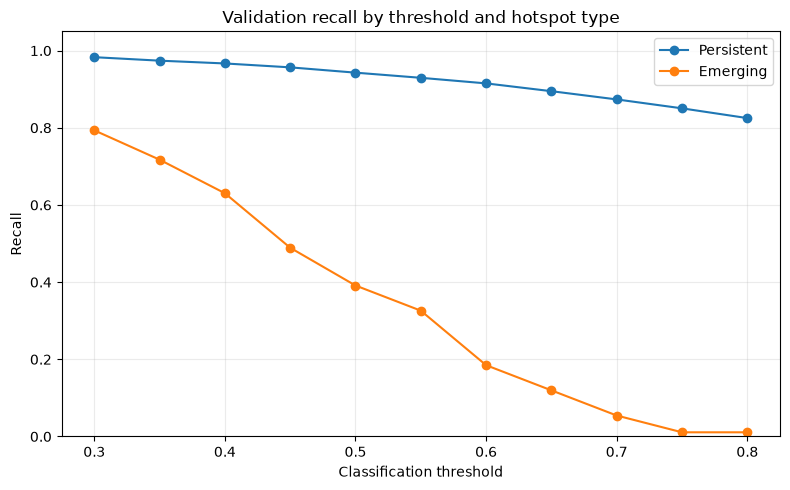

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\figures\recall_threshold_sensitivity.png


In [16]:
# 14. Threshold sensitivity for the 20-feature LR model

val_diag = val.reset_index(drop=True).copy()
val_diag["probability"] = prob_full_val

threshold_rows = []

for threshold in np.arange(0.30, 0.81, 0.05):
    threshold = round(float(threshold), 2)

    for event_type in ["Persistent", "Emerging"]:
        group = val_diag[val_diag["event_type_7d"].eq(event_type)]

        if len(group) == 0:
            recall = np.nan
        else:
            recall = (group["probability"] >= threshold).mean()

        threshold_rows.append({
            "Threshold": threshold,
            "Event Type": event_type,
            "Recall": recall,
        })

threshold_sensitivity = pd.DataFrame(threshold_rows)

fig, ax = plt.subplots(figsize=(8, 5))

for event_type in ["Persistent", "Emerging"]:
    part = threshold_sensitivity[
        threshold_sensitivity["Event Type"].eq(event_type)
    ]
    ax.plot(
        part["Threshold"],
        part["Recall"],
        marker="o",
        label=event_type,
    )

ax.set_title("Validation recall by threshold and hotspot type")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()

fig_path = FIGURES_DIR / "recall_threshold_sensitivity.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 15. Compare predicted-probability distributions

If the model systematically assigns lower probabilities to Emerging positives than to Persistent positives, that is evidence that the strong overall score is partly driven by local persistence.

This is a **diagnostic**, not proof of causality.

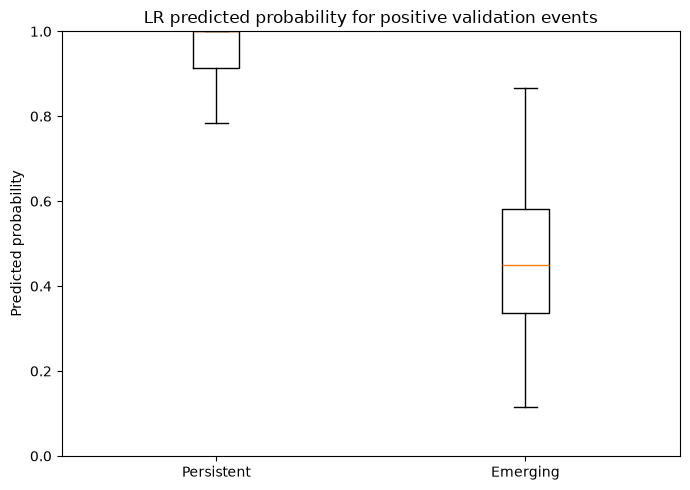

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\figures\positive_probability_boxplot.png


In [18]:
# 15. Probability distribution comparison

persistent_prob = val_diag.loc[
    val_diag["event_type_7d"].eq("Persistent"),
    "probability",
].to_numpy()

emerging_prob = val_diag.loc[
    val_diag["event_type_7d"].eq("Emerging"),
    "probability",
].to_numpy()

fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(
    [persistent_prob, emerging_prob],
    showfliers=False,
)

# Set label secara terpisah supaya kompatibel dengan berbagai versi matplotlib
ax.set_xticks([1, 2])
ax.set_xticklabels(["Persistent", "Emerging"])

ax.set_title("LR predicted probability for positive validation events")
ax.set_ylabel("Predicted probability")
ax.set_ylim(0, 1)

plt.tight_layout()

fig_path = FIGURES_DIR / "positive_probability_boxplot.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 16. Temporal pattern of Emerging detections

This plot shows **the date on which the positive target occurs** (`t+1`), rather than the prediction-input date `t`.

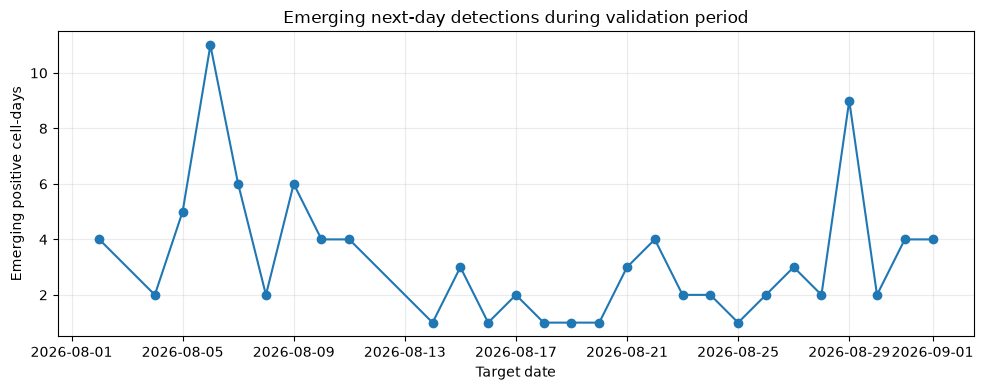

,target_date,emerging_count
3,2026-08-06,11
24,2026-08-29,9
6,2026-08-09,6
4,2026-08-07,6
2,2026-08-05,5
7,2026-08-10,4
8,2026-08-11,4
0,2026-08-02,4
27,2026-09-01,4
26,2026-08-31,4


Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\figures\validation_emerging_daily.png


In [19]:
# 16. Daily emerging detections in validation

val_emerging = val[val["event_type_7d"].eq("Emerging")].copy()

daily_emerging = (
    val_emerging
    .groupby("target_date")
    .size()
    .rename("emerging_count")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    daily_emerging["target_date"],
    daily_emerging["emerging_count"],
    marker="o",
)
ax.set_title("Emerging next-day detections during validation period")
ax.set_xlabel("Target date")
ax.set_ylabel("Emerging positive cell-days")
ax.grid(alpha=0.25)
plt.tight_layout()

fig_path = FIGURES_DIR / "validation_emerging_daily.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()

display(daily_emerging.sort_values("emerging_count", ascending=False).head(10))
print("Saved:", fig_path)

## 17. Preliminary spatial view of Emerging detections

This is **not yet** the final geographic map with rivers/lakes/land mask.

Its purpose is simply to identify which grid cells repeatedly contain Emerging positive detections. Notebook 12 should add coastlines, land/water masking, and a more detailed geographic zoom.

,cell_id,grid_lat,grid_lon,emerging_count
0,Kalimantan_-0.75_108.75,-0.75,108.75,2
4,Kalimantan_-1.50_117.75,-1.50,117.75,2
10,Kalimantan_-3.75_111.75,-3.75,111.75,2
11,Kalimantan_-3.75_112.50,-3.75,112.50,2
8,Kalimantan_-3.00_118.50,-3.00,118.50,2
6,Kalimantan_-2.25_108.00,-2.25,108.00,2
46,Kalimantan_3.75_115.50,3.75,115.50,2
47,Kalimantan_3.75_117.75,3.75,117.75,2
67,Kalimantan_6.75_116.25,6.75,116.25,2
50,Kalimantan_4.50_115.50,4.50,115.50,2


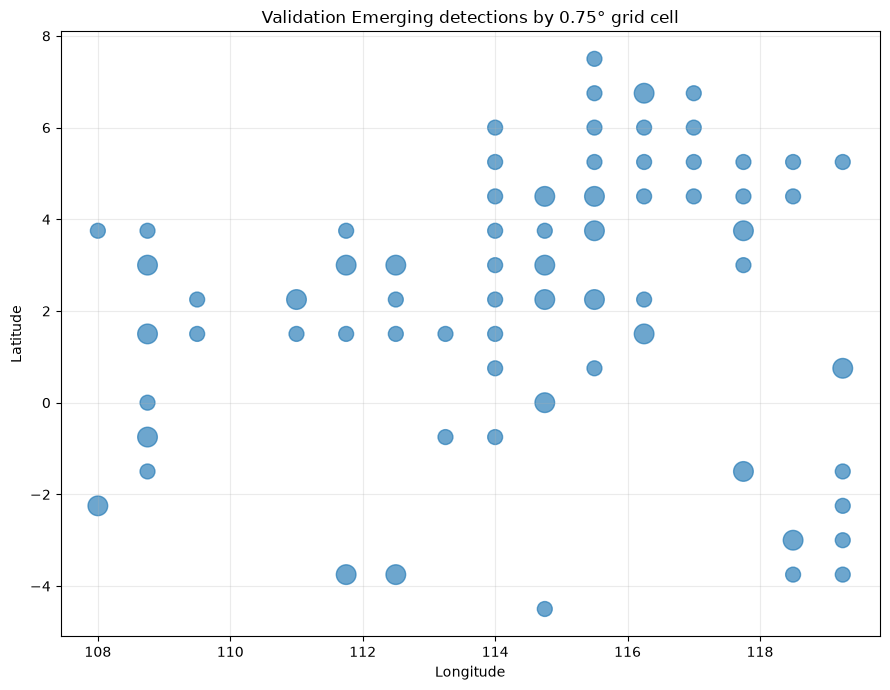

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\figures\validation_emerging_spatial_scatter.png


In [20]:
# 17. Emerging detections by grid cell

emerging_by_cell = (
    val_emerging
    .groupby(["cell_id", "grid_lat", "grid_lon"])
    .size()
    .rename("emerging_count")
    .reset_index()
    .sort_values("emerging_count", ascending=False)
)

display(emerging_by_cell.head(20))

if len(emerging_by_cell) > 0:
    size_scale = 30 + 170 * (
        emerging_by_cell["emerging_count"]
        / emerging_by_cell["emerging_count"].max()
    )

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.scatter(
        emerging_by_cell["grid_lon"],
        emerging_by_cell["grid_lat"],
        s=size_scale,
        alpha=0.65,
    )
    ax.set_title("Validation Emerging detections by 0.75° grid cell")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.25)
    plt.tight_layout()

    fig_path = FIGURES_DIR / "validation_emerging_spatial_scatter.png"
    plt.savefig(fig_path, dpi=160, bbox_inches="tight")
    plt.show()

    print("Saved:", fig_path)
else:
    print("No Emerging validation events under the 7-day definition.")

## 18. Persistence baseline sanity check

A simple persistence baseline predicts tomorrow as active if the **current day `t` is active**.

By construction, a 7-day Emerging event has no activity during `t-6 ... t`, so the persistence baseline must have zero recall on that subgroup.

This is useful for interpreting why a model dominated by fire-history features may struggle on Emerging events.

In [21]:
# 18. Simple persistence baseline on validation

val_persist = val.reset_index(drop=True).copy()
val_persist["persistence_prediction"] = val_persist["fire_active"].astype(int)

overall_persistence = {
    "PR-AUC proxy not reported": np.nan,
    "Precision": precision_score(
        val_persist[TARGET],
        val_persist["persistence_prediction"],
        zero_division=0,
    ),
    "Recall": recall_score(
        val_persist[TARGET],
        val_persist["persistence_prediction"],
        zero_division=0,
    ),
    "F1": f1_score(
        val_persist[TARGET],
        val_persist["persistence_prediction"],
        zero_division=0,
    ),
    "Accuracy": accuracy_score(
        val_persist[TARGET],
        val_persist["persistence_prediction"],
    ),
}

print("Persistence baseline — overall validation")
display(pd.DataFrame([overall_persistence]))

persist_positive_rows = []

for event_type in ["Persistent", "Emerging"]:
    group = val_persist[
        val_persist["event_type_7d"].eq(event_type)
    ]

    persist_positive_rows.append({
        "Event Type": event_type,
        "N Positives": len(group),
        "Recall": (
            group["persistence_prediction"].mean()
            if len(group) > 0
            else np.nan
        ),
    })

print("Persistence baseline — positive subgroups")
display(pd.DataFrame(persist_positive_rows))

Persistence baseline — overall validation


,PR-AUC proxy not reported,Precision,Recall,F1,Accuracy
0,NaN,0.818856,0.810839,0.814828,0.875


Persistence baseline — positive subgroups


,Event Type,N Positives,Recall
0,Persistent,2768,0.837789
1,Emerging,92,0.000000


## 19. Optional test-set diagnostic

Keep this **False during method development**.

The purpose of Notebook 11 is to diagnose the problem using training/validation data. Do not repeatedly inspect September test performance while designing GAT, graph edges, or wind-aware variants.

In [23]:
# 19. Optional test evaluation
# Keep False while developing the next graph-based model.

RUN_TEST = False

if RUN_TEST:
    metrics_fire_test, prob_fire_test = overall_metrics(
        lr_fire, test, features_10, threshold=0.5
    )
    metrics_full_test, prob_full_test = overall_metrics(
        lr_full, test, features_20, threshold=0.5
    )

    print("Overall test:")
    display(pd.DataFrame([
        {"Model": "LR — Fire History Only", **metrics_fire_test},
        {"Model": "LR — Fire History + Weather", **metrics_full_test},
    ]))

    subgroup_test = positive_subgroup_metrics(
        test,
        prob_full_test,
        event_col="event_type_7d",
        threshold=0.5,
    )

    print("20-feature LR — test positive subgroups:")
    display(subgroup_test)
else:
    print("RUN_TEST=False → September test set was not inspected in this notebook.")

RUN_TEST=False → September test set was not inspected in this notebook.


## 20. Save analysis outputs

The saved CSVs are intended for later comparison with:

- GCN/GAT
- temporal GAT
- wind-informed graph variants

The row-level labeled dataset is especially useful because later models can reuse the exact same Persistent/Emerging definition.

In [24]:
# 20. Save outputs

analysis_output_cols = [
    "region",
    "cell_id",
    "date",
    "target_date",
    "grid_lat",
    "grid_lon",
    "fire_active",
    "fire_count",
    "active_days_prev3_incl_t",
    "active_days_prev7_incl_t",
    "target_fire_active_t1",
    "event_type_3d",
    "event_type_7d",
    "split",
]

analysis_output_cols = [
    c for c in analysis_output_cols
    if c in analysis.columns
]

analysis_path = RESULTS_DIR / "emerging_hotspot_labels_kalimantan.csv"
composition7_path = RESULTS_DIR / "event_composition_7d.csv"
composition3_path = RESULTS_DIR / "event_composition_3d.csv"
overall_path = RESULTS_DIR / "lr_overall_validation.csv"
subgroup_path = RESULTS_DIR / "lr_positive_subgroup_validation.csv"
weather_delta_path = RESULTS_DIR / "weather_delta_by_event_type.csv"
threshold_path = RESULTS_DIR / "threshold_sensitivity.csv"
spatial_path = RESULTS_DIR / "validation_emerging_by_cell.csv"

analysis[analysis_output_cols].to_csv(analysis_path, index=False)
composition_7d.to_csv(composition7_path, index=False)
composition_3d.to_csv(composition3_path, index=False)
overall_validation.to_csv(overall_path, index=False)
subgroup_validation.to_csv(subgroup_path, index=False)
weather_delta.to_csv(weather_delta_path, index=False)
threshold_sensitivity.to_csv(threshold_path, index=False)
emerging_by_cell.to_csv(spatial_path, index=False)

print("Saved outputs:")
for path in [
    analysis_path,
    composition7_path,
    composition3_path,
    overall_path,
    subgroup_path,
    weather_delta_path,
    threshold_path,
    spatial_path,
]:
    print("-", path)

Saved outputs:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\emerging_hotspot_labels_kalimantan.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\event_composition_7d.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\event_composition_3d.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\lr_overall_validation.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\lr_positive_subgroup_validation.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\weather_delta_by_event_type.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\threshold_sensitivity.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_hotspot\validation_emerging_by_cell.csv


## 21. Automatic interpretation summary

Use this only as a quick diagnostic. The thesis discussion should still inspect the actual tables and figures.

In [25]:
# 21. Compact interpretation

full_persistent = subgroup_validation[
    (subgroup_validation["Model"].eq("LR — Fire History + Weather")) &
    (subgroup_validation["Event Type"].eq("Persistent"))
].iloc[0]

full_emerging = subgroup_validation[
    (subgroup_validation["Model"].eq("LR — Fire History + Weather")) &
    (subgroup_validation["Event Type"].eq("Emerging"))
].iloc[0]

persistent_recall = full_persistent["Recall"]
emerging_recall = full_emerging["Recall"]
recall_gap = persistent_recall - emerging_recall

print("=== Notebook 11 key diagnostic ===")
print(f"Persistent recall @0.50 : {persistent_recall:.4f}")
print(f"Emerging recall @0.50   : {emerging_recall:.4f}")
print(f"Persistent - Emerging   : {recall_gap:+.4f}")
print()

if np.isnan(recall_gap):
    print("One subgroup is empty; inspect the event definition.")
elif recall_gap >= 0.15:
    print(
        "Strong diagnostic signal: LR is substantially better on Persistent "
        "than Emerging positives."
    )
    print(
        "Next step: test whether neighbor context and wind alignment contain "
        "information specifically for Emerging detections."
    )
elif recall_gap >= 0.05:
    print(
        "Moderate diagnostic signal: LR performs better on Persistent positives, "
        "but the gap is not extremely large."
    )
    print(
        "Next step: continue with wind/spatial analysis, but do not assume graph "
        "modeling will necessarily improve performance."
    )
else:
    print(
        "Little evidence that Emerging positives are the main weakness of LR "
        "under this 7-day definition."
    )
    print(
        "Before building a specialized wind-informed GAT, reconsider the exact "
        "research motivation or test alternative Emerging windows."
    )

=== Notebook 11 key diagnostic ===
Persistent recall @0.50 : 0.9429
Emerging recall @0.50   : 0.3913
Persistent - Emerging   : +0.5516

Strong diagnostic signal: LR is substantially better on Persistent than Emerging positives.
Next step: test whether neighbor context and wind alignment contain information specifically for Emerging detections.


# Decision after Notebook 11

Bring these outputs to the next stage:

1. **Emerging share among positives**
2. **Persistent vs Emerging LR recall**
3. **Fire-history-only vs +weather change on Emerging recall**
4. **Probability distribution difference**
5. **Emerging hotspot locations**

## Recommended next step

### If Emerging recall is clearly lower than Persistent recall

Proceed to:

**Notebook 12 — Spatial zoom + land/water mask**

then:

**Notebook 13 — Wind-direction / neighbor-alignment analysis**

Only after these diagnostics should you build:

**Notebook 14 — GAT baseline**

### If Emerging recall is not clearly lower

Do **not** force the narrative that LR fails on new hotspots.

Instead, treat the result as evidence and revisit the spatial research question before designing a specialized wind-aware model.